In [24]:
import pandas as pd
import matplotlib.pyplot as plt

In [25]:
df = pd.read_csv('newton_molecule_3_3.csv')
df

,indice_atomo,elemento,f_plus,f_minus
0,0,C,0.041571,0.011419
1,1,O,-0.009084,0.030576
2,2,C,0.207340,0.030339
3,3,O,0.000617,0.073076
4,4,C,0.308496,0.035292
5,5,O,0.024962,0.068446
6,6,C,0.504316,-0.164332
7,7,C,-0.572352,0.095887
8,8,C,0.139478,0.074345
9,9,C,0.079535,0.047885


In [26]:
df = pd.read_csv('newton_molecule_0_0.csv')
df[df["elemento"] == "O"]

,indice_atomo,elemento,f_plus,f_minus
7,7,O,0.038520,0.139360
8,8,O,0.004452,0.040547
15,15,O,0.036572,0.053537
16,16,O,0.071308,0.111117
17,17,O,0.122658,0.128965


In [27]:
df = pd.read_csv('newton_molecule_1_1.csv')
df = pd.read_csv('newton_molecule_7_7.csv')
df = pd.read_csv('newton_molecule_15_15.csv')
df
df[df["elemento"] == "O"]

,indice_atomo,elemento,f_plus,f_minus
3,3,O,-0.007429,-0.003748
6,6,O,-0.018600,0.030018
16,16,O,0.002696,0.045984
18,18,O,0.019437,0.063030
30,30,O,0.091712,0.054837
31,31,O,0.070453,0.058042


In [28]:
datos = []

for i in range(42):
    try:
        archivo = f'newton_molecule_{i}_{i}.csv'
        df = pd.read_csv(archivo)

        temp = df[df["elemento"] == "O"].tail(2).copy()
        temp.insert(0, "archivo", archivo)  # identificador del CSV
        
        
        datos.append(temp)

    except:
        print(f'{archivo} not found')
        continue

nuevo_df = pd.concat(datos, ignore_index=True)

nuevo_df

newton_molecule_30_30.csv not found
newton_molecule_37_37.csv not found


,archivo,indice_atomo,elemento,f_plus,f_minus
0,newton_molecule_0_0.csv,16,O,0.071308,0.111117
1,newton_molecule_0_0.csv,17,O,0.122658,0.128965
2,newton_molecule_1_1.csv,27,O,0.050270,0.068714
3,newton_molecule_1_1.csv,28,O,0.083411,0.057065
4,newton_molecule_2_2.csv,21,O,0.109622,0.082127
...,...,...,...,...,...
75,newton_molecule_39_39.csv,33,O,0.069170,0.037802
76,newton_molecule_40_40.csv,26,O,0.086258,0.062104
77,newton_molecule_40_40.csv,29,O,0.013415,0.080927
78,newton_molecule_41_41.csv,27,O,0.106828,0.080332


In [29]:
datos = []

for i in range(42):
    archivo = f"newton_molecule_{i}_{i}.csv"

    try:
        df = pd.read_csv(archivo)

        temp = df[df["elemento"] == "O"].tail(2).reset_index(drop=True)

        if len(temp) == 2:
            fila = {
                # "archivo": i+1,
                "O_1": temp.loc[0, "f_minus"],
                "O_2": temp.loc[1, "f_minus"],
                # "f_plus_1": temp.loc[0, "f_plus"],
                # "f_plus_2": temp.loc[1, "f_plus"],
            }

            datos.append(fila)

    except FileNotFoundError:
        print(f"{archivo} not found")
        continue

nuevo_df = pd.DataFrame(datos)
nuevo_df.index = range(1, len(nuevo_df) + 1)
# nuevo_df.index.name = "archivo"
nuevo_df

newton_molecule_30_30.csv not found
newton_molecule_37_37.csv not found


,O_1,O_2
1,0.111117,0.128965
2,0.068714,0.057065
3,0.082127,0.073014
4,0.106194,0.100106
5,0.059894,0.052748
6,0.100806,0.092337
7,0.125369,0.110592
8,0.076297,0.065751
9,0.091586,0.067214
10,0.012877,0.048903


In [30]:
df_fase1 = pd.read_csv('../df_final_fase1.csv')
df_fase1.index = range(1, len(nuevo_df) + 1)
# df_fase1["electrofilicidad_ev"]
# df_fase1["electrofilicidad_ev"]

nuevo_df["omegak_1"] = None
nuevo_df["omegak_2"] = None

nuevo_df["omegak_1"] = df_fase1["electrofilicidad_ev"]*nuevo_df["O_1"]
nuevo_df["omegak_2"] = df_fase1["electrofilicidad_ev"]*nuevo_df["O_2"]
nuevo_df.to_csv('resultados_fukui.csv', index=False)
nuevo_df

,O_1,O_2,omegak_1,omegak_2
1,0.111117,0.128965,0.423423,0.491435
2,0.068714,0.057065,0.268153,0.222694
3,0.082127,0.073014,0.350904,0.311968
4,0.106194,0.100106,0.481101,0.453522
5,0.059894,0.052748,0.185041,0.162965
6,0.100806,0.092337,0.222013,0.203361
7,0.125369,0.110592,0.524079,0.462306
8,0.076297,0.065751,0.281092,0.242241
9,0.091586,0.067214,0.338616,0.248505
10,0.012877,0.048903,0.040437,0.153569


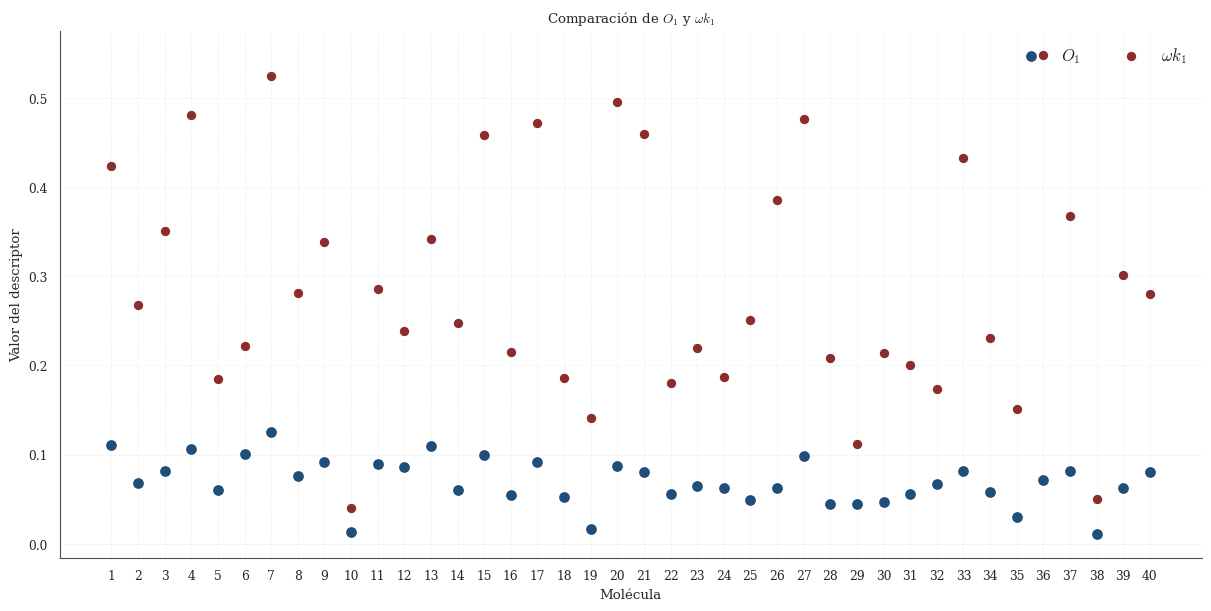

In [31]:
import matplotlib.pyplot as plt

 
moleculas = range(1, len(nuevo_df) + 1)

# Figura con estilo académico
fig, ax = plt.subplots(figsize=(12, 6), constrained_layout=True)

# Scatter de O_1
ax.scatter(
    moleculas,
    nuevo_df["O_1"],
    color='#1f4e79',
    s=80,
    edgecolors='white',
    linewidths=1.2,
    alpha=1.0,
    label=r'$O_1$',
    zorder=3
 )

# Scatter de ωk_1
ax.scatter(
    moleculas,
    nuevo_df["omegak_1"],
    color='#8a2d2d',
    s=60,
    edgecolors='white',
    linewidths=1.0,
    alpha=1.0,
    label=r'$\omega k_1$',
    zorder=3
 )

ax.set_xlabel('Molécula')
ax.set_ylabel('Valor del descriptor')
ax.set_title('Comparación de $O_1$ y $\omega k_1$')
ax.set_xticks(list(moleculas))
ax.grid(True, which='major', linestyle='--', linewidth=0.6, alpha=0.35, zorder=0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(frameon=False, ncol=2, loc='upper right', fontsize=12)

# Guardar figura para tesis
#plt.savefig('O1_vs_omegak1_tesis_scatter.png', dpi=300, bbox_inches='tight')

plt.show()

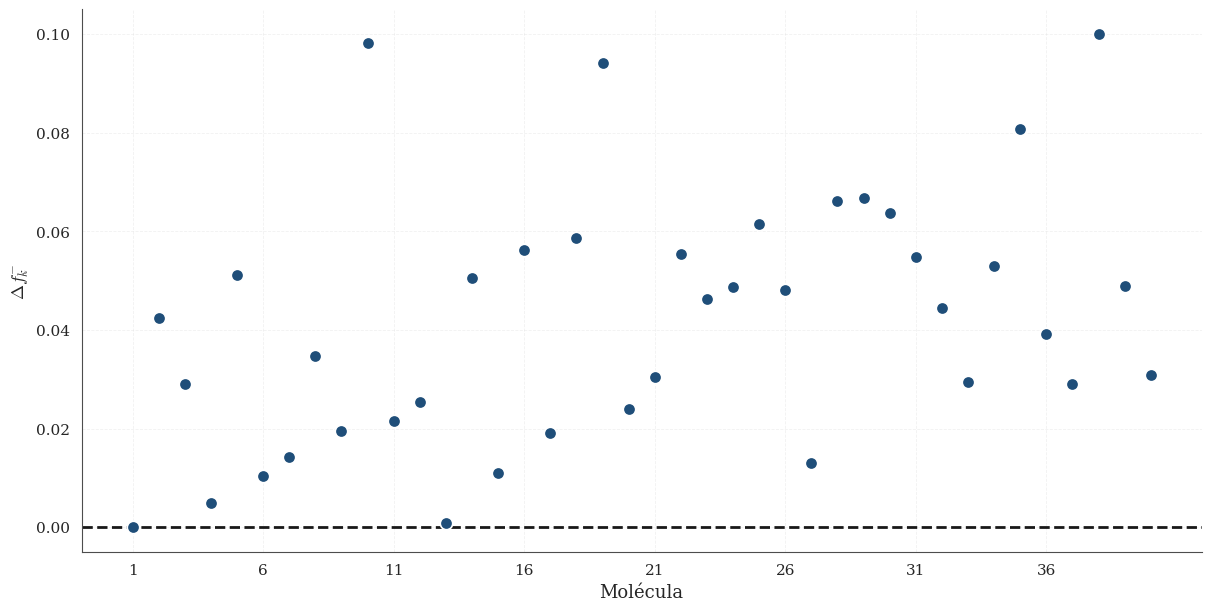

In [32]:
import matplotlib.pyplot as plt

# Delta absoluto respecto a la molécula 1
delta_o_1 = (nuevo_df["O_1"] - nuevo_df["O_1"].iloc[0]).abs()

# Eje x: número de molécula
moleculas = range(1, len(nuevo_df) + 1)

plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['DejaVu Serif'],
    'axes.labelsize': 13,
    'axes.titlesize': 15,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'legend.fontsize': 12,
})

fig, ax = plt.subplots(figsize=(12, 6), constrained_layout=True)

ax.scatter(
    moleculas,
    delta_o_1,
    s=80,
    color='#1f4e79',
    edgecolors='white',
    linewidths=1.2,
    alpha=1.0,
    label=r'$|\Delta O_1|$',
    zorder=3
)

ax.axhline(0, color='black', linewidth=2.0, linestyle='--', alpha=0.9, zorder=2)

ax.set_xlabel('Molécula')
ax.set_ylabel('$\Delta f_k^{-}$')
# ax.set_title('Scatter del cambio absoluto de $O_1$ respecto a la molécula 1')
ax.set_xticks(range(1, len(nuevo_df) + 1, 5))
ax.grid(True, which='major', linestyle='--', linewidth=0.6, alpha=0.35, zorder=0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
# ax.legend(frameon=False, loc='best', fontsize=12)

plt.savefig('scatter_delta_f_o1.png', dpi=300, bbox_inches='tight')

plt.show()

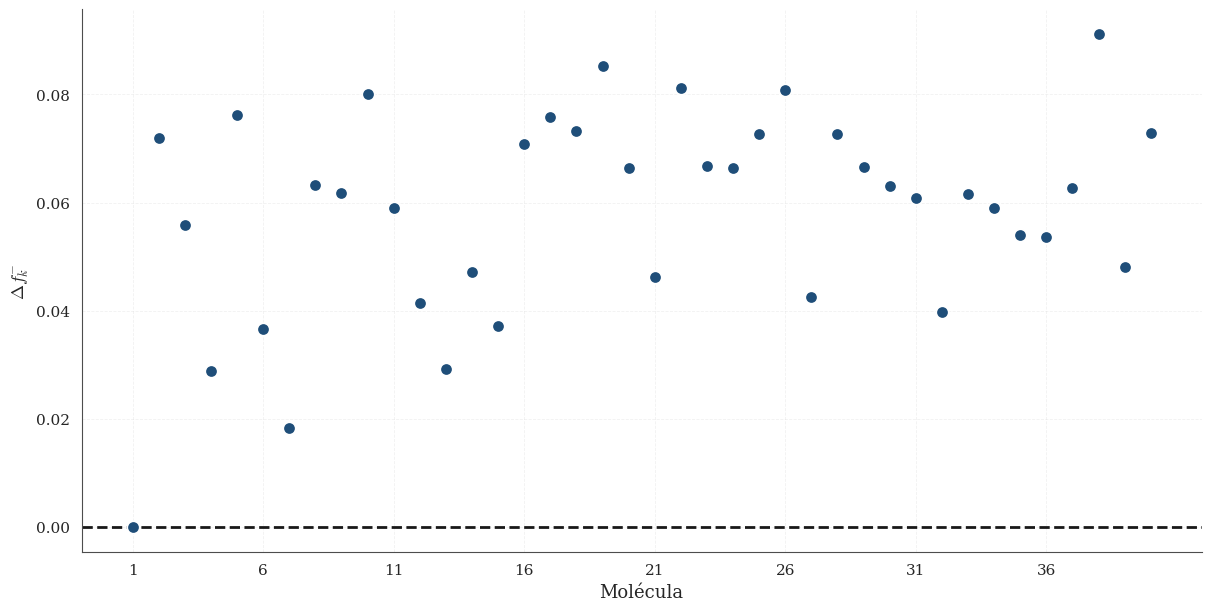

In [33]:
import matplotlib.pyplot as plt

# Delta absoluto respecto a la molécula 1
delta_o_1 = (nuevo_df["O_2"] - nuevo_df["O_2"].iloc[0]).abs()

# Eje x: número de molécula
moleculas = range(1, len(nuevo_df) + 1)

plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['DejaVu Serif'],
    'axes.labelsize': 13,
    'axes.titlesize': 15,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'legend.fontsize': 12,
})

fig, ax = plt.subplots(figsize=(12, 6), constrained_layout=True)

ax.scatter(
    moleculas,
    delta_o_1,
    s=80,
    color='#1f4e79',
    # color='#E67E22',
    edgecolors='white',
    linewidths=1.2,
    alpha=1.0,
    label=r'$|\Delta O_1|$',
    zorder=3
)

ax.axhline(0, color='black', linewidth=2.0, linestyle='--', alpha=0.9, zorder=2)

ax.set_xlabel('Molécula')
ax.set_ylabel('$\Delta f_k^{-}$')
# ax.set_title('Scatter del cambio absoluto de $O_1$ respecto a la molécula 1')
ax.set_xticks(range(1, len(nuevo_df) + 1, 5))
ax.grid(True, which='major', linestyle='--', linewidth=0.6, alpha=0.35, zorder=0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
# ax.legend(frameon=False, loc='best', fontsize=12)

plt.savefig('scatter_delta_f_o2.png', dpi=300, bbox_inches='tight')

plt.show()

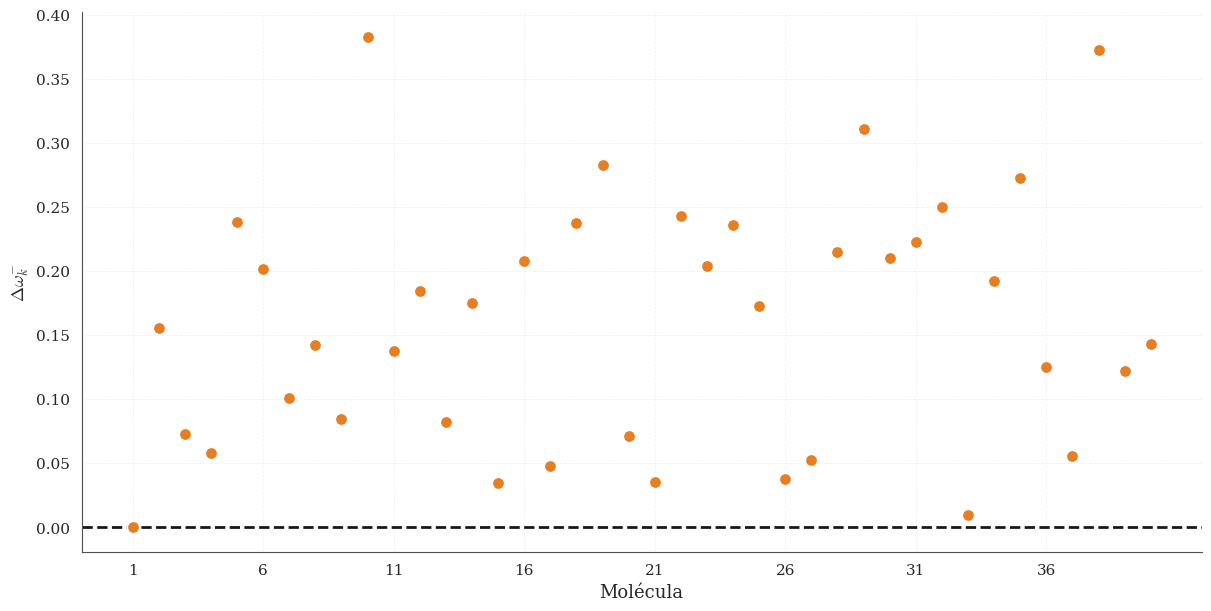

In [34]:
import matplotlib.pyplot as plt

# Delta absoluto respecto a la molécula 1
delta_o_1 = (nuevo_df["omegak_1"] - nuevo_df["omegak_1"].iloc[0]).abs()

# Eje x: número de molécula
moleculas = range(1, len(nuevo_df) + 1)

plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['DejaVu Serif'],
    'axes.labelsize': 13,
    'axes.titlesize': 15,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'legend.fontsize': 12,
})

fig, ax = plt.subplots(figsize=(12, 6), constrained_layout=True)

ax.scatter(
    moleculas,
    delta_o_1,
    s=80,
    # color='#1f4e79',
    color='#E67E22',
    edgecolors='white',
    linewidths=1.2,
    alpha=1.0,
    label=r'$|\Delta O_1|$',
    zorder=3
)

ax.axhline(0, color='black', linewidth=2.0, linestyle='--', alpha=0.9, zorder=2)

ax.set_xlabel('Molécula')
ax.set_ylabel('$\Delta \omega_{k}^{-}$')
# ax.set_title('Scatter del cambio absoluto de $O_1$ respecto a la molécula 1')
ax.set_xticks(range(1, len(nuevo_df) + 1, 5))
ax.grid(True, which='major', linestyle='--', linewidth=0.6, alpha=0.35, zorder=0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
# ax.legend(frameon=False, loc='best', fontsize=12)

plt.savefig('scatter_delta_omegak_o1.png', dpi=300, bbox_inches='tight')

plt.show()

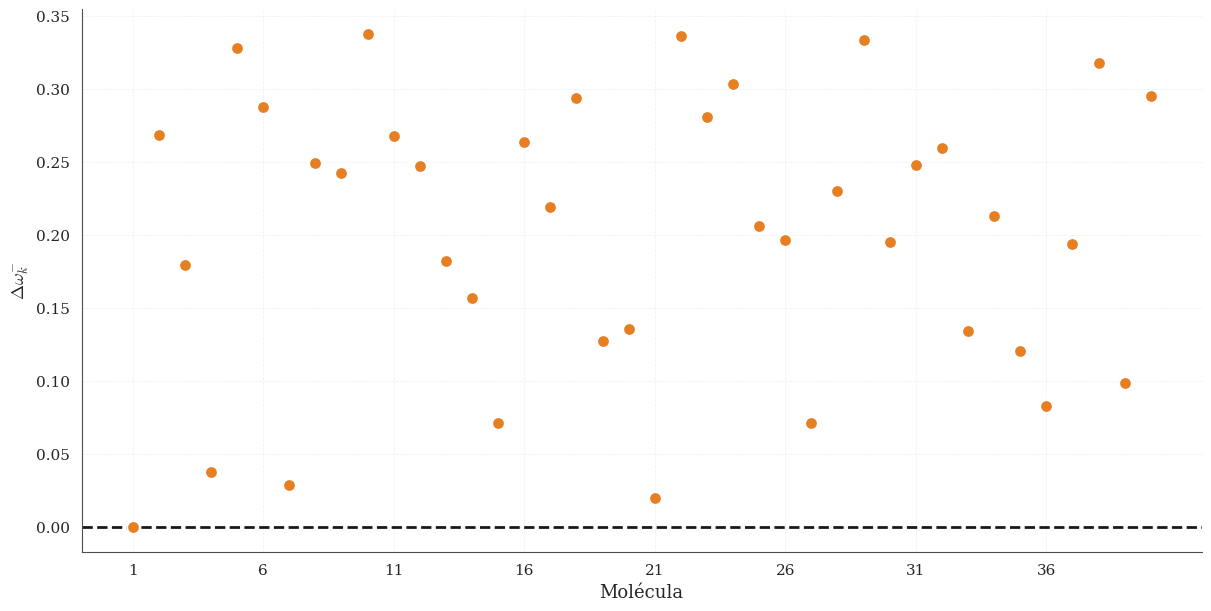

In [35]:
import matplotlib.pyplot as plt

# Delta absoluto respecto a la molécula 1
delta_o_1 = (nuevo_df["omegak_2"] - nuevo_df["omegak_2"].iloc[0]).abs()

# Eje x: número de molécula
moleculas = range(1, len(nuevo_df) + 1)

plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['DejaVu Serif'],
    'axes.labelsize': 13,
    'axes.titlesize': 15,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'legend.fontsize': 12,
})

fig, ax = plt.subplots(figsize=(12, 6), constrained_layout=True)

ax.scatter(
    moleculas,
    delta_o_1,
    s=80,
    # color='#1f4e79',
    color='#E67E22',
    edgecolors='white',
    linewidths=1.2,
    alpha=1.0,
    label=r'$|\Delta O_1|$',
    zorder=3
)

ax.axhline(0, color='black', linewidth=2.0, linestyle='--', alpha=0.9, zorder=2)

ax.set_xlabel('Molécula')
ax.set_ylabel('$\Delta \omega_{k}^{-}$')
# ax.set_title('Scatter del cambio absoluto de $O_1$ respecto a la molécula 1')
ax.set_xticks(range(1, len(nuevo_df) + 1, 5))
ax.grid(True, which='major', linestyle='--', linewidth=0.6, alpha=0.35, zorder=0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
# ax.legend(frameon=False, loc='best', fontsize=12)

plt.savefig('scatter_delta_omegak_o2.png', dpi=300, bbox_inches='tight')

plt.show()

In [36]:
df_fase2 =pd.concat([df_fase1[["ID","SMILES_Quiral","MW","electrofilicidad_ev"]], nuevo_df[["O_1","O_2","omegak_1","omegak_2"]]], axis=1)
df_fase2.to_csv('df_fase2.csv', index=False)
df_fase2

,ID,SMILES_Quiral,MW,electrofilicidad_ev,O_1,O_2,omegak_1,omegak_2
1,ART,C[C@@H]1CC[C@H]2[C@H](C(=O)O[C@H]3[C@@]24[C@H]...,282.336,3.810616,0.111117,0.128965,0.423423,0.491435
2,ART-Der-1,C[C@H]1[C@H](OCc2ccc(O)c(O)c2)O[C@@H]2O[C@@]3(...,406.475,3.902464,0.068714,0.057065,0.268153,0.222694
3,ART-Der-2,C#CCO[C@H]1O[C@@H]2O[C@@]3(C)CC[C@H]4[C@H](C)C...,322.401,4.272718,0.082127,0.073014,0.350904,0.311968
4,ART-Der-3,CO[C@H]1O[C@@H]2O[C@@]3(C)CC[C@@H]4[C@H](C)CC[...,298.379,4.530412,0.106194,0.100106,0.481101,0.453522
5,ART-Der-4,C[C@H]1[C@H](OCCCN2CCOCC2)O[C@@H]2O[C@]3(C)CC[...,411.539,3.089479,0.059894,0.052748,0.185041,0.162965
6,ART-Der-5,CCO[C@@H]1O[C@@H]2O[C@@]3(C)CC[C@H]4[C@H](C)CC...,312.406,2.202386,0.100806,0.092337,0.222013,0.203361
7,ART-Der-6,C[C@H]1[C@H](OCC(=O)C(F)(F)F)O[C@H]2O[C@]3(C)C...,394.386,4.180293,0.125369,0.110592,0.524079,0.462306
8,ART-Der-7,Cc1cc(N)cc(CO[C@@H]2O[C@@H]3O[C@@]4(C)CC[C@H]5...,404.507,3.684197,0.076297,0.065751,0.281092,0.242241
9,ART-Der-8,C=C(CO[C@@H]1O[C@H]2O[C@]3(C)CC[C@@H]4[C@H](C)...,368.470,3.697242,0.091586,0.067214,0.338616,0.248505
10,ART-Der-9,C[C@@H]1[C@@H](OCc2ccccc2OCC(=O)O)O[C@@H]2O[C@...,448.512,3.140265,0.012877,0.048903,0.040437,0.153569


### Empiezo el análisis general de la dustribución de los dos oxígenos

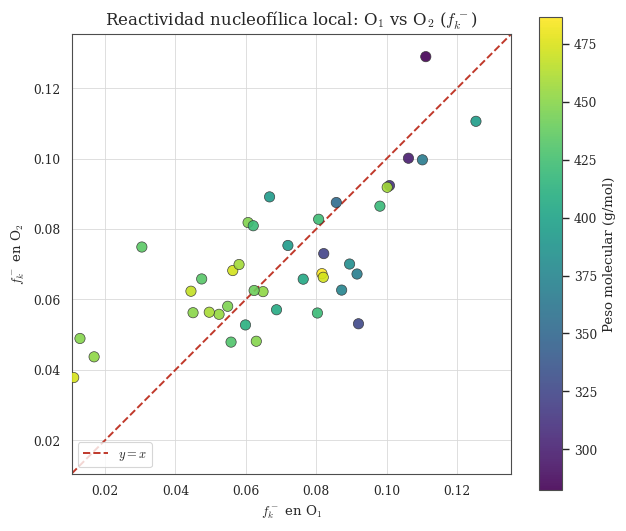

In [37]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""Scatter O1 vs O2 con diagonal y=x. Usa la columna MW del CSV."""
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------ CONFIGURACION ------------------
DESCRIPTOR = "f"          # "f" -> f- (O_1/O_2)  |  "wk" -> wk- (omegak_1/2)
COLOR_POR  = "MW"         # "MW" | None (un solo tono amarillo)
ARCHIVO    = "df_fase2.csv"
# ---------------------------------------------------

df = pd.read_csv(ARCHIVO)

if DESCRIPTOR == "f":
    c1, c2, sym = "O_1", "O_2", r"$f_k^-$"
else:
    c1, c2, sym = "omegak_1", "omegak_2", r"$\omega_k^-$"

x, y = df[c1], df[c2]
lo = min(x.min(), y.min()) * 0.95
hi = max(x.max(), y.max()) * 1.05
n_O1 = int((x > y).sum())
n_O2 = int((y > x).sum())

sns.set_theme(style="whitegrid", context="paper")
mpl.rcParams.update({"font.family": "serif", "axes.edgecolor": "#4d4d4d",
    "axes.linewidth": 0.8, "grid.color": "#d9d9d9", "grid.linewidth": 0.6})

fig, ax = plt.subplots(figsize=(6.4, 6))

# diagonal y=x
ax.plot([lo, hi], [lo, hi], color="#c0392b", lw=1.4, ls="--", zorder=1,
        label="$y = x$")

# puntos
if COLOR_POR:
    sc = ax.scatter(x, y, c=df[COLOR_POR], cmap="viridis", s=55,
                    edgecolor="#333333", linewidth=0.5, alpha=0.9, zorder=3)
    cb = fig.colorbar(sc, ax=ax, shrink=0.85)
    cb.set_label("Peso molecular (g/mol)")
else:
    ax.scatter(x, y, color=(241/255, 239/255, 179/255), s=55,
               edgecolor="#333333", linewidth=0.5, alpha=0.9, zorder=3)

ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect("equal")
ax.set_xlabel(f"{sym} en O$_1$")
ax.set_ylabel(f"{sym} en O$_2$")
ax.set_title(f"Reactividad nucleofílica local: O$_1$ vs O$_2$ ({sym})", fontsize=12)

# regiones de dominancia
# ax.text(0.05, 0.92, f"O$_2$ más reactivo\n(n = {n_O2})", transform=ax.transAxes,
#         ha="left", va="top", fontsize=9, color="#555")
# ax.text(0.95, 0.08, f"O$_1$ más reactivo\n(n = {n_O1})", transform=ax.transAxes,
#         ha="right", va="bottom", fontsize=9, color="#555")
ax.legend(loc="lower left", frameon=True, fontsize=9)

fig.tight_layout()
fig.savefig("scatter_O1_vs_O2.png", dpi=300, bbox_inches="tight")


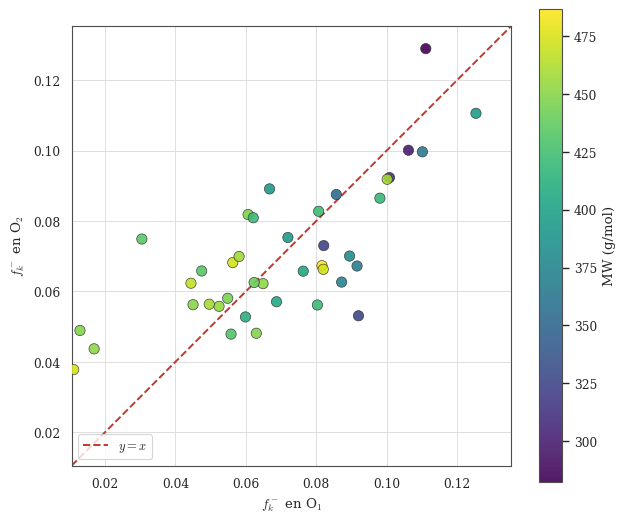

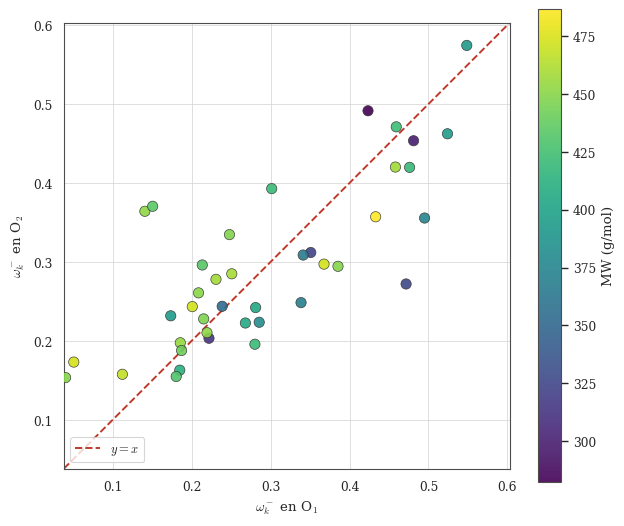

In [38]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""Scatter O1 vs O2 con diagonal y=x, para f- y wk-. Usa la columna MW del CSV."""
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------ CONFIGURACION ------------------
COLOR_POR = "MW"          # "MW" | None (un solo tono amarillo)
ARCHIVO   = "df_fase2.csv"
# ---------------------------------------------------

df = pd.read_csv(ARCHIVO)

sns.set_theme(style="whitegrid", context="paper")
mpl.rcParams.update({"font.family": "serif", "axes.edgecolor": "#4d4d4d",
    "axes.linewidth": 0.8, "grid.color": "#d9d9d9", "grid.linewidth": 0.6})


def hacer_scatter(descriptor, archivo_salida):
    if descriptor == "f":
        c1, c2, sym = "O_1", "O_2", r"$f_k^-$"
    else:
        c1, c2, sym = "omegak_1", "omegak_2", r"$\omega_k^-$"

    x, y = df[c1], df[c2]
    lo = min(x.min(), y.min()) * 0.95
    hi = max(x.max(), y.max()) * 1.05
    n_O1 = int((x > y).sum())
    n_O2 = int((y > x).sum())

    fig, ax = plt.subplots(figsize=(6.4, 6))

    # diagonal y=x
    ax.plot([lo, hi], [lo, hi], color="#c0392b", lw=1.4, ls="--", zorder=1,
            label="$y = x$")

    # puntos
    if COLOR_POR:
        sc = ax.scatter(x, y, c=df[COLOR_POR], cmap="viridis", s=55,
                        edgecolor="#333333", linewidth=0.5, alpha=0.9, zorder=3)
        cb = fig.colorbar(sc, ax=ax, shrink=0.85)
        cb.set_label("MW (g/mol)")
    else:
        ax.scatter(x, y, color=(241/255, 239/255, 179/255), s=55,
                   edgecolor="#333333", linewidth=0.5, alpha=0.9, zorder=3)

    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect("equal")
    ax.set_xlabel(f"{sym} en O$_1$")
    ax.set_ylabel(f"{sym} en O$_2$")
    # ax.set_title(f"Reactividad nucleofílica local: O$_1$ vs O$_2$ ({sym})", fontsize=12)

    # regiones de dominancia
    # ax.text(0.05, 0.92, f"O$_2$ más reactivo\n(n = {n_O2})", transform=ax.transAxes,
    #         ha="left", va="top", fontsize=9, color="#555")
    # ax.text(0.95, 0.08, f"O$_1$ más reactivo\n(n = {n_O1})", transform=ax.transAxes,
    #         ha="right", va="bottom", fontsize=9, color="#555")

    ax.legend(loc="lower left", frameon=True, fontsize=9)
    fig.tight_layout()
    fig.savefig(archivo_salida, dpi=300, bbox_inches="tight")


hacer_scatter("f",  "scatter_O1_vs_O2_f.png")
hacer_scatter("wk", "scatter_O1_vs_O2_wk.png")

### Cambios en los oxígenos respecto a la artemisinina

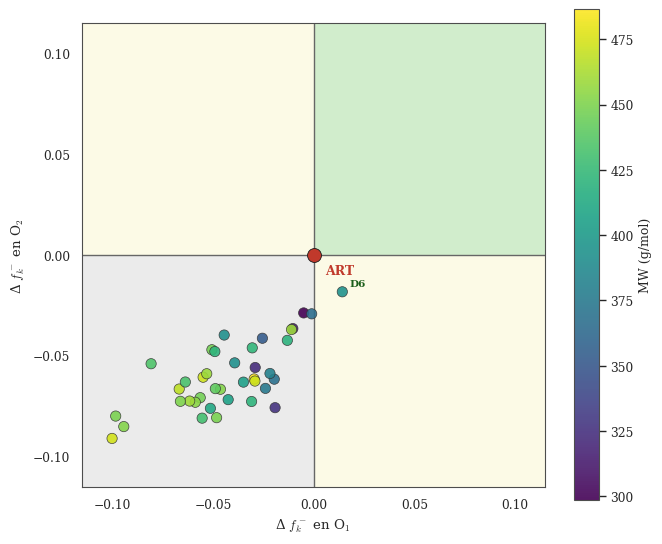

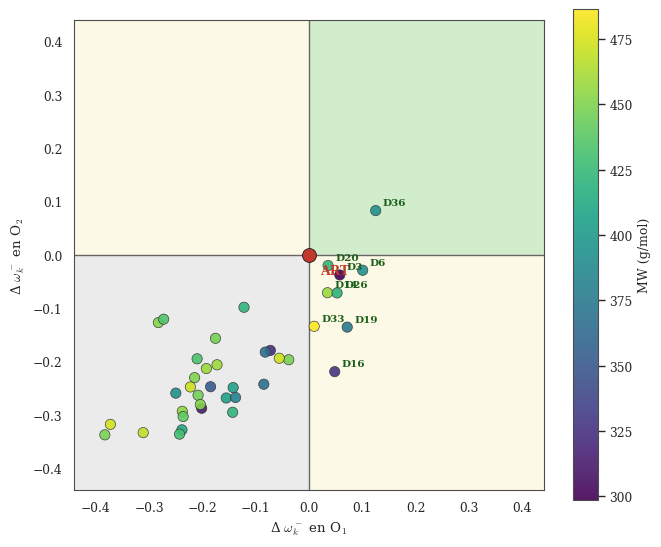

In [41]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
Scatter con signo de los cambios respecto a ART, UNA FIGURA POR DESCRIPTOR.
Eje X = Δ en O1 ; Eje Y = Δ en O2  (Δ = derivado - ART).
Cuadrantes: verde = más reactivo que ART en ambos O ; gris = menos en ambos ; crema = mixto.
"""
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import seaborn as sns

ARCHIVO = "df_fase2.csv"
df = pd.read_csv(ARCHIVO)
art = df[df["ID"] == "ART"].iloc[0]
der = df[df["ID"] != "ART"].copy().reset_index(drop=True)
der["lab"] = der["ID"].str.replace("ART-Der-", "D")

sns.set_theme(style="white", context="paper")
mpl.rcParams.update({"font.family": "serif", "axes.edgecolor": "#4d4d4d",
    "axes.linewidth": 0.8})

VERDE = (0.82, 0.93, 0.80); GRIS = (0.92, 0.92, 0.92); CREMA = (0.99, 0.98, 0.90)

# (col_O1, col_O2, simbolo)
PANELS = [("O_1", "O_2", r"$f_k^-$"),
          ("omegak_1", "omegak_2", r"$\omega_k^-$")]


def hacer_figura(c1, c2, sym):
    x = der[c1] - art[c1]
    y = der[c2] - art[c2]
    m = max(abs(x).max(), abs(y).max()) * 1.15
    lo, hi = -m, m

    fig, ax = plt.subplots(figsize=(6.8, 6.4))

    # cuadrantes
    ax.add_patch(Rectangle((0, 0), hi, hi, color=VERDE, zorder=0))
    ax.add_patch(Rectangle((lo, lo), -lo, -lo, color=GRIS, zorder=0))
    ax.add_patch(Rectangle((lo, 0), -lo, hi, color=CREMA, zorder=0))
    ax.add_patch(Rectangle((0, lo), hi, -lo, color=CREMA, zorder=0))
    ax.axhline(0, color="#666", lw=1.0, zorder=1)
    ax.axvline(0, color="#666", lw=1.0, zorder=1)

    sc = ax.scatter(x, y, c=der["MW"], cmap="viridis", s=55,
                    edgecolor="#333333", linewidth=0.5, alpha=0.9, zorder=3)

    # ART en el origen
    ax.scatter([0], [0], marker="o", s=100, color="#c0392b", edgecolor="k",
               linewidth=0.6, zorder=5)
    ax.annotate("ART", (0, 0), textcoords="offset points", xytext=(8, -14),
                fontsize=9, color="#c0392b", fontweight="bold")

    # etiquetar derivados con algún Δ>0
    mask = (x > 0) | (y > 0)
    for i in der.index[mask]:
        ax.annotate(der.loc[i, "lab"], (x[i], y[i]),
                    textcoords="offset points", xytext=(5, 4), fontsize=7.5,
                    color="#1a5e1a", fontweight="bold", zorder=6)

    n_pp = int(((x > 0) & (y > 0)).sum())
    # ax.text(0.97, 0.97, f"más reactivo que ART\nen O$_1$ y O$_2$  (n={n_pp})",
    #         transform=ax.transAxes, ha="right", va="top", fontsize=8.5, color="#1a5e1a")
    # ax.text(0.03, 0.03, "menos reactivo\nen ambos",
    #         transform=ax.transAxes, ha="left", va="bottom", fontsize=8.5, color="#777")

    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect("equal")
    ax.set_xlabel(f"Δ {sym} en O$_1$ ")
    ax.set_ylabel(f"Δ {sym} en O$_2$ ")
    # ax.set_title(f"Cambio en {sym} respecto a la artemisinina", fontsize=12)
    cb = fig.colorbar(sc, ax=ax, shrink=0.82); cb.set_label("MW (g/mol)", fontsize=9)

    fig.tight_layout()

    return fig

cont = 1
for c1, c2, sym in PANELS:
    fig = hacer_figura(c1, c2, sym)
    fig.savefig(f"delta_art_{cont}.png", dpi=300, bbox_inches="tight")
    cont +=1

plt.show()   # muestra las figuras en pantalla; no guarda archivos

box_f_halogeno.png  p=0.383  Cliff_delta=+0.128
box_f_aromaticidad.png  p=0.00275  Cliff_delta=-0.419
box_f_nitrogeno.png  p=0.0946  Cliff_delta=-0.230
box_wk_halogeno.png  p=0.82  Cliff_delta=-0.034
box_wk_aromaticidad.png  p=0.126  Cliff_delta=-0.214
box_wk_nitrogeno.png  p=0.0368  Cliff_delta=-0.287


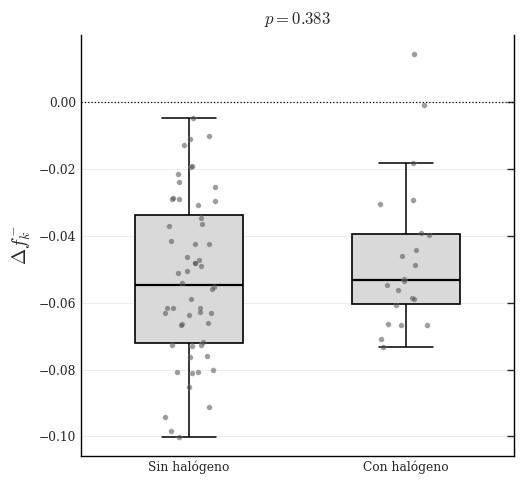

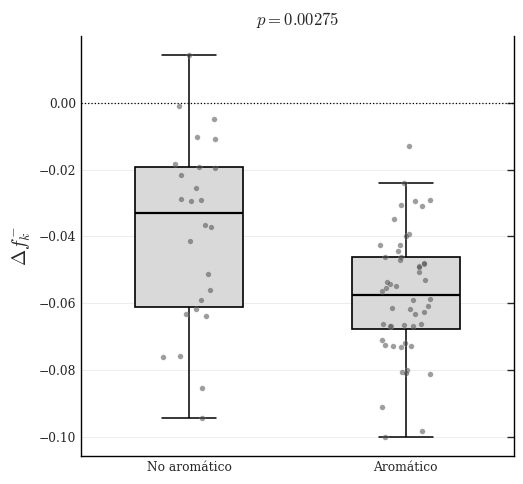

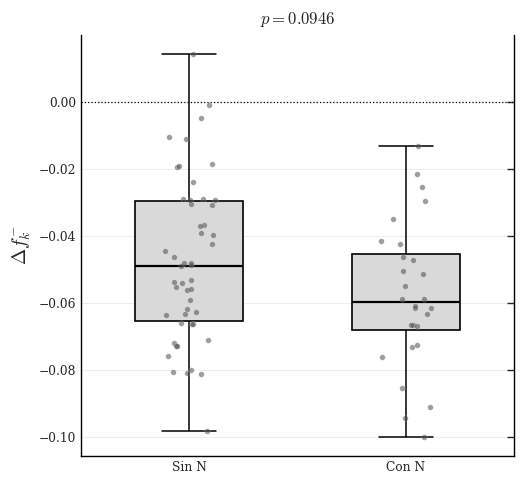

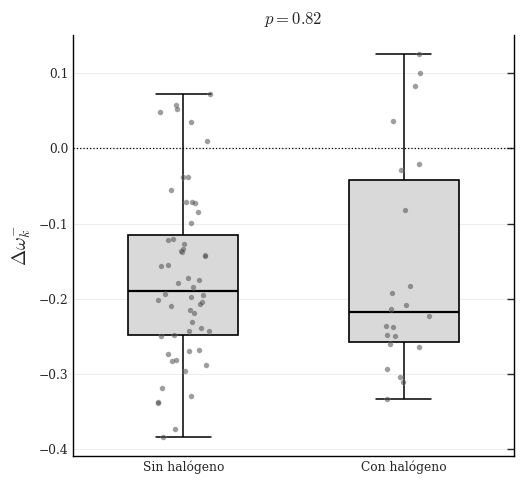

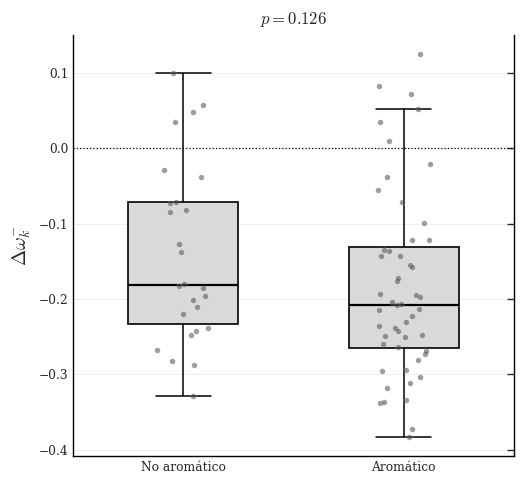

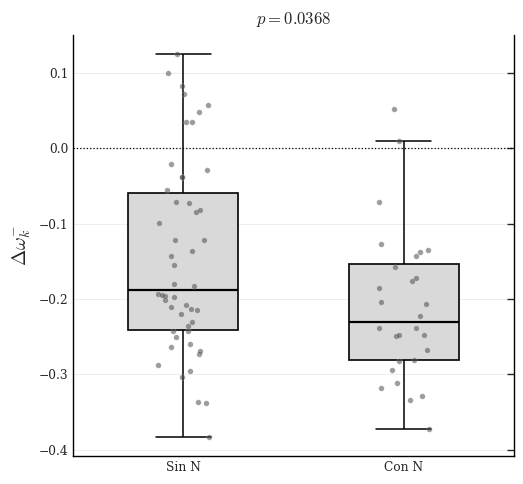

In [42]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from rdkit import Chem
from rdkit.Chem import rdMolDescriptors

ARCHIVO = "df_fase2.csv"
df = pd.read_csv(ARCHIVO)
art = df[df["ID"] == "ART"].iloc[0]
der = df[df["ID"] != "ART"].copy().reset_index(drop=True)

def feats(smi):
    m = Chem.MolFromSmiles(smi)
    return dict(
        halogeno = int(any(a.GetSymbol() in ("F","Cl","Br","I") for a in m.GetAtoms())),
        tiene_N  = int(any(a.GetSymbol()=="N" for a in m.GetAtoms())),
        aromatico= int(rdMolDescriptors.CalcNumAromaticRings(m) > 0),
    )
der = pd.concat([der, der["SMILES_Quiral"].apply(lambda s: pd.Series(feats(s)))], axis=1)

der["dO1_f"]  = der["O_1"]      - art["O_1"]
der["dO2_f"]  = der["O_2"]      - art["O_2"]
der["dO1_wk"] = der["omegak_1"] - art["omegak_1"]
der["dO2_wk"] = der["omegak_2"] - art["omegak_2"]

def a_largo(cO1, cO2):
    return pd.concat([
        der[["halogeno","tiene_N","aromatico",cO1]].rename(columns={cO1:"delta"}),
        der[["halogeno","tiene_N","aromatico",cO2]].rename(columns={cO2:"delta"}),
    ], ignore_index=True)

def cliffs_delta(a, b):
    """Cliff's delta: -1..+1, tamano de efecto no parametrico."""
    a = np.asarray(a); b = np.asarray(b)
    n = len(a)*len(b)
    gt = sum((x > b).sum() for x in a)
    lt = sum((x < b).sum() for x in a)
    return (gt - lt) / n

DESCRIPTORES = [("dO1_f","dO2_f",  r"$\Delta f_k^{-}$",       "f"),
                ("dO1_wk","dO2_wk",r"$\Delta \omega_k^{-}$",  "wk")]
CATS = [("halogeno",  {0:"Sin halógeno",1:"Con halógeno"}, "halogeno",  "Presencia de halógeno"),
        ("aromatico", {0:"No aromático",1:"Aromático"},     "aromaticidad","Aromaticidad"),
        ("tiene_N",   {0:"Sin N",1:"Con N"},                "nitrogeno", "Presencia de nitrógeno")]

# ---- estetica paper de fisica: serif tipo LaTeX, escala de grises ----
mpl.rcParams.update({
    "font.family":"serif",
    "font.serif":["DejaVu Serif","CMU Serif","Times New Roman"],
    "mathtext.fontset":"cm",         # Computer Modern para las matematicas
    "figure.facecolor":"white",
    "axes.facecolor":"white",
    "axes.edgecolor":"black",
    "axes.linewidth":1.0,
    "xtick.direction":"in","ytick.direction":"in",
    "xtick.top":False,"ytick.right":True,
    "font.size":12,
})

GRIS_CAJA = "#d9d9d9"    # relleno de la caja
GRIS_PUNTO= "#4d4d4d"    # puntos

def una_figura(Ldata, col, mapa, sym, titulo, archivo):
    orden = [mapa[0], mapa[1]]
    sub = Ldata.copy(); sub["cat"] = sub[col].map(mapa)

    fig, ax = plt.subplots(figsize=(5.4, 5.0))
    ax.set_axisbelow(True)
    ax.yaxis.grid(True, color="#ededed", linewidth=0.7)
    ax.xaxis.grid(False)

    # boxplot en gris
    sns.boxplot(data=sub, x="cat", y="delta", order=orden, ax=ax,
        width=0.5, linewidth=1.2,
        boxprops=dict(facecolor=GRIS_CAJA, edgecolor="black"),
        medianprops=dict(color="black", linewidth=1.6),
        whiskerprops=dict(color="black", linewidth=1.1),
        capprops=dict(color="black", linewidth=1.1),
        flierprops=dict(marker="", alpha=0),      # sin outliers (los ponemos aparte)
        showfliers=False)

    # puntos jitter grises encima
    sns.stripplot(data=sub, x="cat", y="delta", order=orden, ax=ax,
        color=GRIS_PUNTO, size=4, alpha=0.55, jitter=0.12,
        edgecolor="white", linewidth=0.2)

    ax.axhline(0, color="black", lw=0.9, ls=":", zorder=1)

    # estadistica: p (Mann-Whitney) + Cliff's delta
    g0 = Ldata[Ldata[col]==0]["delta"]; g1 = Ldata[Ldata[col]==1]["delta"]
    p  = stats.mannwhitneyu(g0, g1).pvalue
    d  = cliffs_delta(g1, g0)   # g1 (con la propiedad) respecto a g0
    # ax.set_title(rf"$p = {p:.3g}$,   $\delta = {d:+.2f}$", fontsize=12, pad=8)
    ax.set_title(rf"$p = {p:.3g}$", fontsize=12, pad=8)

    ax.set_xlabel("")
    ax.set_ylabel(sym, fontsize=14)
    ax.spines["top"].set_visible(False)

    fig.tight_layout()
    fig.savefig(archivo, dpi=300, bbox_inches="tight")
    print(f"{archivo}  p={p:.3g}  Cliff_delta={d:+.3f}")
    return fig

for cO1,cO2,sym,suf_d in DESCRIPTORES:
    L = a_largo(cO1,cO2)
    for col,mapa,suf_c,titulo in CATS:
        una_figura(L, col, mapa, sym, titulo, f"box_{suf_d}_{suf_c}.png")

plt.show()